Name: Gayatri Kakde
Roll no: 4337
Subject: Deep Learning

In [ ]:
# Import Libraries
import numpy as np
import pandas as pd
import random
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Conv2D,Dense,MaxPooling2D
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist

In [ ]:
# Load MNIST Data and Assign to X, y
(images, labels), _ = mnist.load_data()
X = images
y = labels

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Split Data into Train and Test Sets
(X_train, y_train),(X_test, y_test) = mnist.load_data()

In [ ]:
print(X_train.shape)

(60000, 28, 28)


In [ ]:
X_train[0].min(),X_train[0].max()

(np.uint8(0), np.uint8(255))

In [ ]:
# Normalize Training and Test Data
X_train = (X_train - 0.0) / (255.0 - 0.0)
X_test = (X_test - 0.0) / (255.0 - 0.0)
X_train[0].min(), X_train[0].max()
(0.0, 1.0)

(0.0, 1.0)

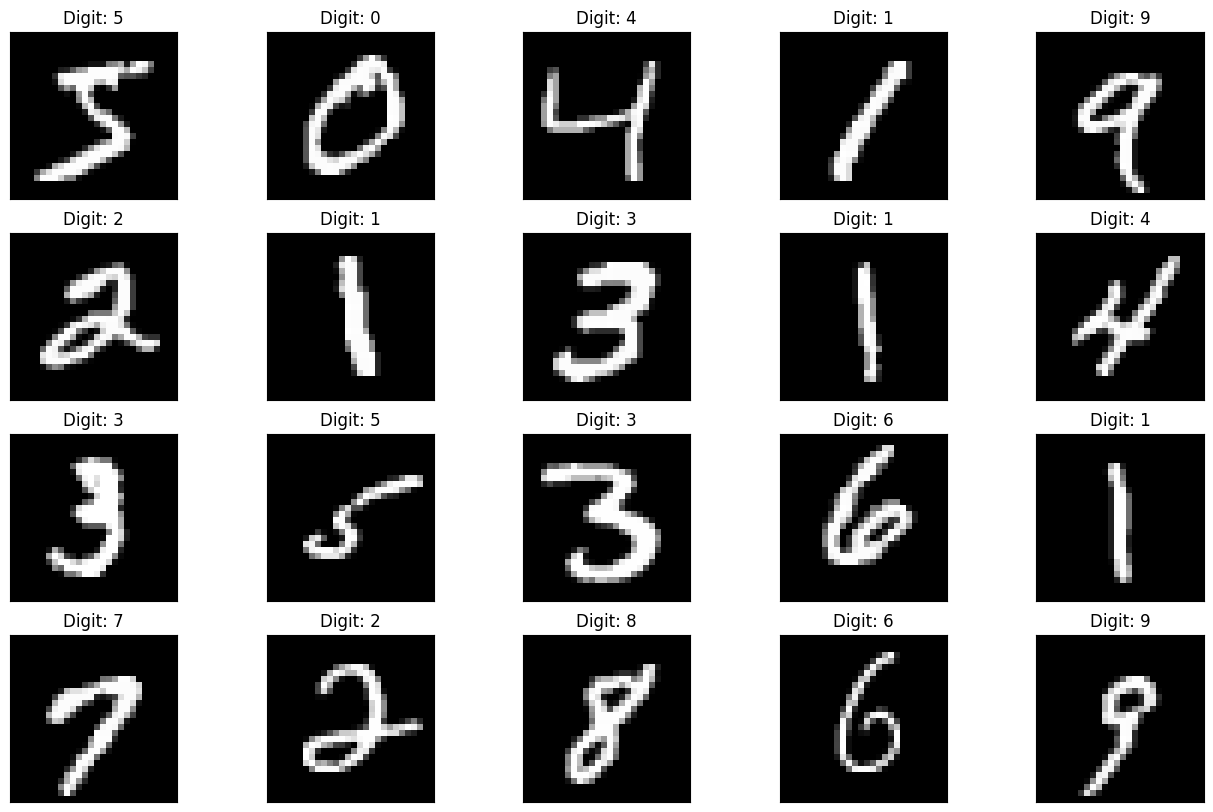

In [ ]:
# Define Plot Digit Function and Plot First 20 Images
def plot_digit(image, digit, plt, i):
    plt.subplot(4, 5, i + 1)
    plt.imshow(image, cmap=plt.get_cmap('gray'))
    plt.title(f"Digit: {digit}")
    plt.xticks([])
    plt.yticks([])
plt.figure(figsize=(16, 10))
for i in range(20):
   plot_digit(X_train[i], y_train[i], plt, i)
plt.show()

In [ ]:
X_tarin = X_train.reshape((X_train.shape+ (1,)))
X_test = X_test.reshape((X_test.shape+(1,)))

In [ ]:
y_train[0:20]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9],
      dtype=uint8)

In [ ]:
# Build CNN Architecture
model = Sequential([
Conv2D(32,(3,3), activation="relu",input_shape=(28,28,1)),
MaxPooling2D((2,2)),
Flatten(),
Dense(100,activation="relu"),
Dense(10,activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Configure Model Optimizer and Loss Function
optimizer = SGD(learning_rate=0.01, momentum=0.9)
model.compile(
optimizer=optimizer,
loss="sparse_categorical_crossentropy",
metrics=["accuracy"]
)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       540,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 542,230 (2.07 MB)

 Trainable params: 542,230 (2.07 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Split Data into Train/Validation and Fit Model
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2,random_state=42)

Model_log = model.fit(
X_train,
y_train,
epochs=10,
batch_size=15,
verbose=1,
validation_data=(X_val, y_val)
)

Epoch 1/10
3200/3200 ━━━━━━━━━━━━━━━━━━━━ 41s 13ms/step - accuracy: 0.1076 - loss: 2.5316 - val_accuracy: 0.1102 - val_loss: 2.3034
Epoch 2/10
3200/3200 ━━━━━━━━━━━━━━━━━━━━ 46s 14ms/step - accuracy: 0.1087 - loss: 2.3027 - val_accuracy: 0.1082 - val_loss: 2.3024
Epoch 3/10
3200/3200 ━━━━━━━━━━━━━━━━━━━━ 37s 12ms/step - accuracy: 0.1071 - loss: 2.3028 - val_accuracy: 0.1102 - val_loss: 2.3014
Epoch 4/10
3200/3200 ━━━━━━━━━━━━━━━━━━━━ 40s 13ms/step - accuracy: 0.1086 - loss: 2.3028 - val_accuracy: 0.1102 - val_loss: 2.3020
Epoch 5/10
3200/3200 ━━━━━━━━━━━━━━━━━━━━ 41s 13ms/step - accuracy: 0.1088 - loss: 2.3027 - val_accuracy: 0.1082 - val_loss: 2.3026
Epoch 6/10
3200/3200 ━━━━━━━━━━━━━━━━━━━━ 40s 12ms/step - accuracy: 0.1094 - loss: 2.3029 - val_accuracy: 0.1016 - val_loss: 2.3032
Epoch 7/10
3200/3200 ━━━━━━━━━━━━━━━━━━━━ 38s 12ms/step - accuracy: 0.1103 - loss: 2.3028 - val_accuracy: 0.1082 - val_loss: 2.3022
Epoch 8/10
3200/3200 ━━━━━━━━━━━━━━━━━━━━ 38s 12ms/step - accuracy: 0.1101 -

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


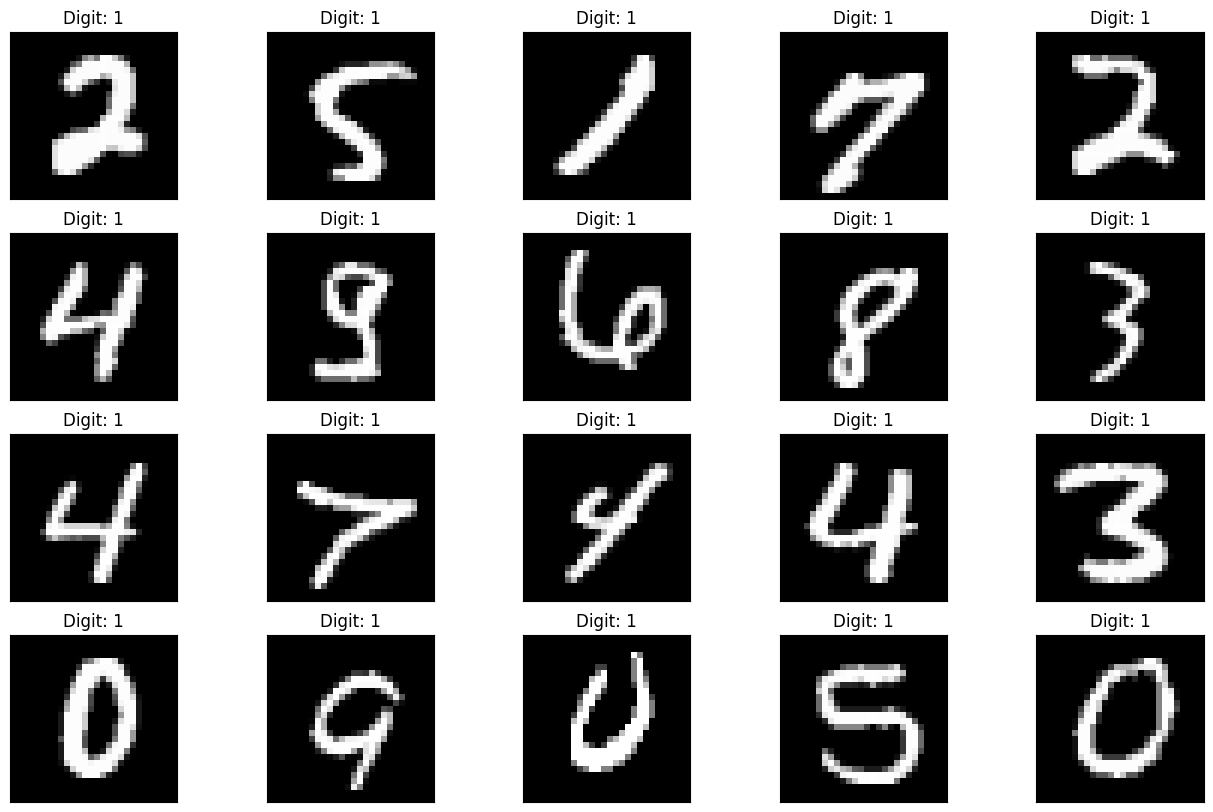

In [ ]:
# Predict and Plot 20 Random Samples from Test Set
plt.figure(figsize=(16, 10))
for i in range(20):
     image = random.choice(X_test).squeeze()
     digit = np.argmax(model.predict(image.reshape((1, 28, 28, 1)))[0], axis=-1)
     plot_digit(image, digit, plt, i)
plt.show()

In [ ]:
# Evaluate Overall Test Accuracy Score
predictions = np.argmax(model.predict(X_test),axis=-1)
accuracy_score(y_test,predictions)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


0.1135

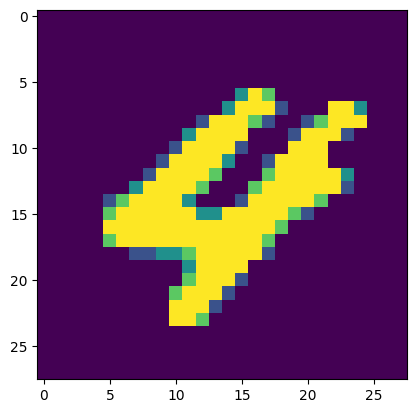

In [ ]:
# Display Random Image from Test Set
n = random.randint(0,9999)
plt.imshow(X_test[n])
plt.show()